<a href="https://colab.research.google.com/github/lewinskie254/stock-market-prediction/blob/main/predict_stock_prices_FCNeuralNets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import pandas as pd
import yfinance as yf
import torch
import torch.nn as nn
from tqdm.notebook import tqdm, trange
from statsmodels.tsa.statespace.sarimax import SARIMAX
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

In [4]:
ticker = "AAPL"
stock = yf.Ticker(ticker)

# Get historical market data (e.g., past 1 year, daily interval)
hist = stock.history(period="1y", interval="1h")
print(hist.head())

# Get basic company info / metadata
info = stock.info
print(info.get("longName"), info.get("regularMarketPrice"))

# Get dividends and stock splits
dividends = stock.dividends
splits = stock.splits

                                 Open        High         Low       Close  \
Datetime                                                                    
2025-11-07 09:30:00-05:00  269.795013  272.290009  267.269989  271.579987   
2025-11-07 10:30:00-05:00  271.559998  271.970001  269.480011  269.529999   
2025-11-07 11:30:00-05:00  269.519989  269.890015  268.320007  269.109985   
2025-11-07 12:30:00-05:00  269.114990  269.140015  268.058807  268.450012   
2025-11-07 13:30:00-05:00  268.450012  268.660004  267.095001  267.250000   

                            Volume  Dividends  Stock Splits  
Datetime                                                     
2025-11-07 09:30:00-05:00  7855390        0.0           0.0  
2025-11-07 10:30:00-05:00  3991205        0.0           0.0  
2025-11-07 11:30:00-05:00  3276263        0.0           0.0  
2025-11-07 12:30:00-05:00  2041690        0.0           0.0  
2025-11-07 13:30:00-05:00  2217548        0.0           0.0  
Apple Inc. 342.37


In [5]:
hist.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Datetime,,,,,,,
2025-11-07 09:30:00-05:00,269.795013,272.290009,267.269989,271.579987,7855390,0.0,0.0
2025-11-07 10:30:00-05:00,271.559998,271.970001,269.480011,269.529999,3991205,0.0,0.0
2025-11-07 11:30:00-05:00,269.519989,269.890015,268.320007,269.109985,3276263,0.0,0.0
2025-11-07 12:30:00-05:00,269.114990,269.140015,268.058807,268.450012,2041690,0.0,0.0
2025-11-07 13:30:00-05:00,268.450012,268.660004,267.095001,267.250000,2217548,0.0,0.0


In [6]:
data = hist.drop(columns= ['Dividends', 'Stock Splits'])

In [7]:
data["year"] = data.index.year
data["month"] = data.index.month
data["day"] = data.index.dayofweek
data["date"] = data.index.day
data["hour"] = data.index.hour
data["cos_hour"] = np.cos(data.index.hour / 60 * 2 * np.pi)
data["sin_hour"] = np.sin(data.index.hour / 60 * 2 * np.pi)

In [8]:
data.index[:20]

DatetimeIndex(['2025-11-07 09:30:00-05:00', '2025-11-07 10:30:00-05:00',
               '2025-11-07 11:30:00-05:00', '2025-11-07 12:30:00-05:00',
               '2025-11-07 13:30:00-05:00', '2025-11-07 14:30:00-05:00',
               '2025-11-07 15:30:00-05:00', '2025-11-10 09:30:00-05:00',
               '2025-11-10 10:30:00-05:00', '2025-11-10 11:30:00-05:00',
               '2025-11-10 12:30:00-05:00', '2025-11-10 13:30:00-05:00',
               '2025-11-10 14:30:00-05:00', '2025-11-10 15:30:00-05:00',
               '2025-11-11 09:30:00-05:00', '2025-11-11 10:30:00-05:00',
               '2025-11-11 11:30:00-05:00', '2025-11-11 12:30:00-05:00',
               '2025-11-11 13:30:00-05:00', '2025-11-11 14:30:00-05:00'],
              dtype='datetime64[ns, America/New_York]', name='Datetime', freq=None)

In [9]:
train = data.iloc[:int(len(data) * 0.7)]
test = data.iloc[int(len(data) * 0.7):int(len(data) * 0.85)]
val = data.iloc[int(len(data) * 0.85):]

In [10]:
from sklearn.preprocessing import StandardScaler

features = ["Open", "High", "Low", "Volume"]

scaler = StandardScaler()

train[features] = scaler.fit_transform(train[features])

val[features] = scaler.transform(val[features])

test[features] = scaler.transform(test[features])

/tmp/ipykernel_1024/3278748688.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train[features] = scaler.fit_transform(train[features])
/tmp/ipykernel_1024/3278748688.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  val[features] = scaler.transform(val[features])
/tmp/ipykernel_1024/3278748688.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.py

In [12]:
class DataWindow():
  def __init__(self, input_width, label_width, shift,train_df=train, val_df=val, test_df=test, label_columns=None):
    self.train_df = train_df
    self.val_df = val_df
    self.test_df = test_df
    self.label_columns = label_columns
    if label_columns is not None:
      self.label_columns_indices = {name: i for i, name in enumerate(label_columns)}
    self.column_indices = {name: i for i, name in enumerate(train_df.columns)}
    self.input_width = input_width
    self.label_width = label_width
    self.shift = shift
    self.total_window_size = input_width + shift
    self.input_slice = slice(0, input_width)
    self.input_indices =  np.arange(self.total_window_size)[self.input_slice]
    self.label_start = self.total_window_size - self.label_width
    self.labels_slice = slice(self.label_start, None)
    self.label_indices =np.arange(self.total_window_size)[self.labels_slice]

  def split_to_inputs_labels(self, features):
    inputs = features[:, self.input_slice, :]
    labels = features[:, self.labels_slice, :]
    if self.label_columns is not None:
      labels = torch.stack([labels[:,:,self.column_indices[name]] for name in  self.label_columns],axis=-1)
    inputs.set_shape([None, self.input_width, None])
    labels.set_shape([None, self.label_width, None])
    return inputs, labels

    def make_dataset(self, data):
      data = np.array(data, dtype=np.float32)
      ds = tf.keras.preprocessing.timeseries_dataset_from_array(
        data=data,
        targets=None,
        sequence_length=self.total_window_size,
        sequence_stride=1,
        shuffle=True,
        batch_size=32
      )
      ds = ds.map(self.split_to_inputs_labels)
      return ds

In [13]:
class WindowDataset(Dataset):
    def __init__(self, data, input_width, label_width, shift, label_columns=None):
        super().__init__()
        # Convert dataframe to a float32 tensor
        self.data = torch.as_tensor(data.to_numpy(dtype="float32"),dtype=torch.float32)
        self.input_width = input_width
        self.label_width = label_width
        self.shift = shift
        self.total_window_size = input_width + shift
        self.label_start = self.total_window_size - label_width

        # Map column names to their tensor indices
        self.column_indices = { name: i for i, name in enumerate(data.columns)}
        self.label_columns = label_columns

        if label_columns is not None:
            self.label_columns_indices = [ self.column_indices[name] for name in label_columns]
        else:
            self.label_columns_indices = None

    def __len__(self):
        return len(self.data) - self.total_window_size + 1

    def __getitem__(self, index):
        # Extract the complete time window
        window = self.data[index : index + self.total_window_size]
        # Separate inputs and labels
        inputs = window[:self.input_width]
        labels = window[self.label_start:]
        # Select specific target columns if provided
        if self.label_columns_indices is not None:
            labels = labels[:, self.label_columns_indices]

        return inputs, labels

In [14]:
class DataWindow:
    def __init__(self,input_width=7,label_width=1,shift=1,train_df=train,val_df=val,test_df=test,label_columns=['Close']):

        self.train_df = train_df
        self.val_df = val_df
        self.test_df = test_df

        self.input_width = input_width
        self.label_width = label_width
        self.shift = shift
        self.label_columns = label_columns

        self.total_window_size = input_width + shift
        self.input_slice = slice(0, input_width)
        self.label_start = self.total_window_size - label_width
        self.labels_slice = slice(self.label_start, None)

        self.column_indices = {name: i for i, name in enumerate(train_df.columns)}
        self.label_columns_indices = {name: i for i, name in enumerate(label_columns)} if label_columns is not None else None

        self.input_indices = np.arange(self.total_window_size)[:input_width]
        self.label_indices = np.arange(self.total_window_size)[self.label_start:]

    def make_dataset(self, data, batch_size=32, shuffle=False):
        dataset = WindowDataset(
            data=data,
            input_width=self.input_width,
            label_width=self.label_width,
            shift=self.shift,
            label_columns=self.label_columns
        )

        return DataLoader(dataset,batch_size=batch_size,shuffle=shuffle,drop_last=False)


    def plot(self, model=None, plot_col='Close', max_subplots=3):
        inputs, labels = self.sample_batch
        plot_col_index = self.column_indices[plot_col]

        # Find the target column's position in the labels tensor
        if self.label_columns is not None:
            label_col_index = self.label_columns_indices.get(plot_col)
        else:
            label_col_index = plot_col_index

        max_n = min(max_subplots, len(inputs))
        plt.figure(figsize=(12, 8))

        for n in range(max_n):
            plt.subplot(max_n, 1, n + 1)
            plt.ylabel(f'{plot_col} [scaled]')
            # Plot historical inputs
            plt.plot(self.input_indices,inputs[n, :, plot_col_index].cpu().numpy(),label='Inputs',marker='.')

            # Plot actual labels, if this feature is a target
            if label_col_index is not None:
                plt.scatter(self.label_indices,labels[n, :, label_col_index].cpu().numpy(),edgecolors='k',marker='s',label='Labels',c='green',s=64)
                # Plot predictions
                if model is not None:
                    model.eval()
                    device = next(model.parameters()).device
                    print("inputs shape", inputs.shape)
                    print("inputs closes", inputs[n, :, plot_col_index])
                    with torch.no_grad():
                        predictions = model(
                            inputs.to(device).flatten(start_dim=1)
                        )
                    predictions = predictions.reshape(-1, self.label_width, len(self.label_columns))
                    print(f"prediction {n, }", predictions[n])
                    plt.scatter(self.label_indices,predictions[n, :, label_col_index].cpu().numpy(),marker='X',edgecolors='k',label='Predictions',c='red',s=64)
            if n == 0:
                plt.legend()
            plt.xlabel('Time steps')
        plt.tight_layout()
        plt.show()



    @property
    def train(self):
        return self.make_dataset(self.train_df, shuffle=True)

    @property
    def val(self):
        return self.make_dataset(self.val_df)

    @property
    def test(self):
        return self.make_dataset(self.test_df)

    @property
    def sample_batch(self):
        result = next(iter(self.train))
        self.sample = result
        return self.sample


In [15]:
hourly_window = DataWindow()

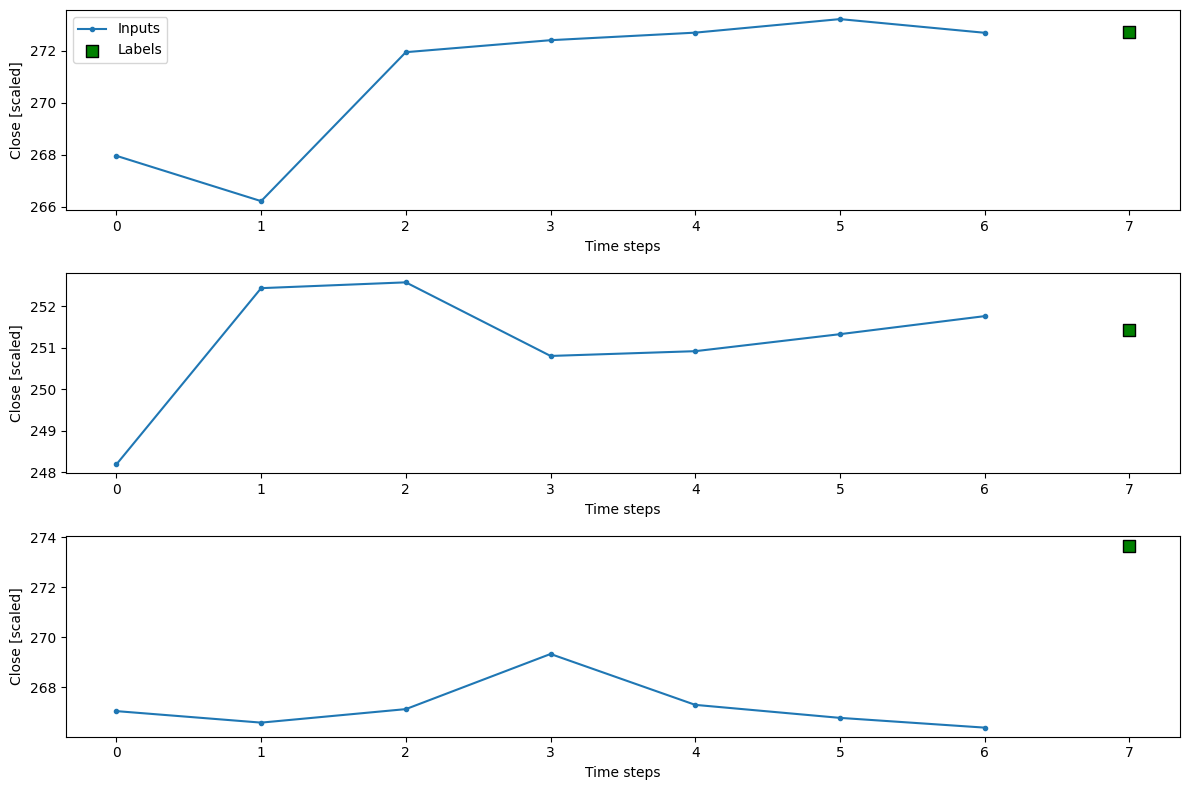

In [16]:
hourly_window.plot()

In [17]:
input_width = 7
label_width = 1

In [18]:
def make_model(output_width):
  model = nn.Sequential(
    nn.Flatten(start_dim=1),
    nn.Linear(7 * 12, 50),
    nn.ReLU(),
    nn.Linear(50, output_width)
  )
  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  model = model.to(device)

  return model

In [19]:
model = make_model(1)

inputs shape torch.Size([32, 7, 12])
inputs closes tensor([300.4500, 297.4300, 298.6150, 296.8100, 295.8350, 295.1850, 295.8800])
prediction (0,) tensor([[-82.0970]])
inputs shape torch.Size([32, 7, 12])
inputs closes tensor([298.3700, 299.0750, 298.1650, 299.2900, 301.9695, 301.8100, 303.1200])
prediction (1,) tensor([[-81.6251]])
inputs shape torch.Size([32, 7, 12])
inputs closes tensor([260.7600, 260.5100, 260.5705, 261.4300, 262.3000, 263.6100, 264.4300])
prediction (2,) tensor([[-80.7637]])


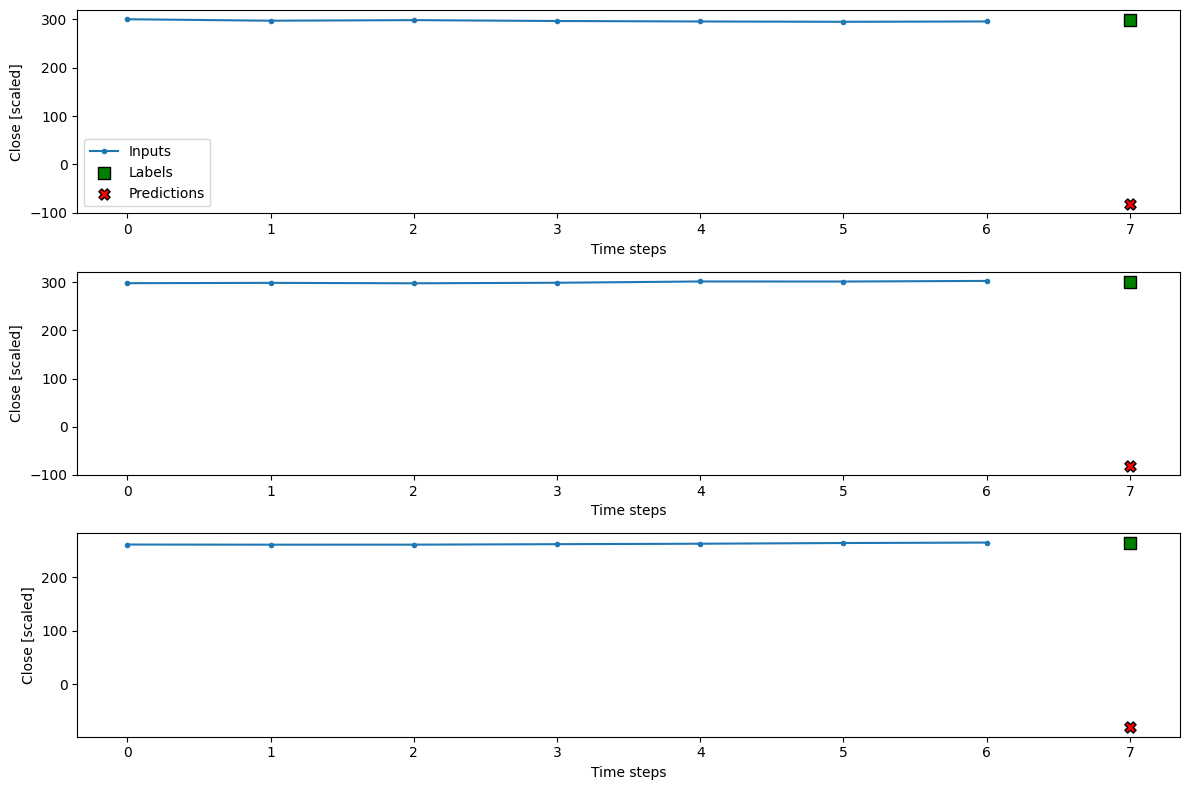

In [20]:
hourly_window.plot(model=model)

In [23]:

def train_loop(model, n_epochs, data_window, learning_rate):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loss_fn = nn.MSELoss()

    train_loss = []
    val_loss = []

    for epoch in tqdm(range(n_epochs)):
        model.train()
        running_train_loss = 0.0

        for inputs, labels in data_window.train:
            optimizer.zero_grad()
            preds = model(inputs.flatten(start_dim=1))
            loss = loss_fn(preds, labels.squeeze(-1))
            loss.backward()
            optimizer.step()
            running_train_loss += loss.item()
        epoch_train_loss = running_train_loss / len(data_window.train)
        train_loss.append(epoch_train_loss)

        # Validation
        model.eval()
        running_val_loss = 0.0

        with torch.no_grad():
            for inputs, labels in data_window.val:
                preds = model(inputs.flatten(start_dim=1))
                loss = loss_fn(preds, labels.squeeze(-1))
                running_val_loss += loss.item()
        epoch_val_loss = running_val_loss / len(data_window.val)
        val_loss.append(epoch_val_loss)
    return train_loss, val_loss

In [24]:
tl, vl = train_loop(model, 1000, hourly_window, 0.001)

  0%|          | 0/1000 [00:00<?, ?it/s]

In [54]:
def plot_losses(train_loss, val_loss, start_idx=0):
    plt.figure(figsize=(10, 6))
    plt.plot(train_loss[start_idx:], label="Train Loss")
    plt.plot(val_loss[start_idx:], label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training and Validation Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

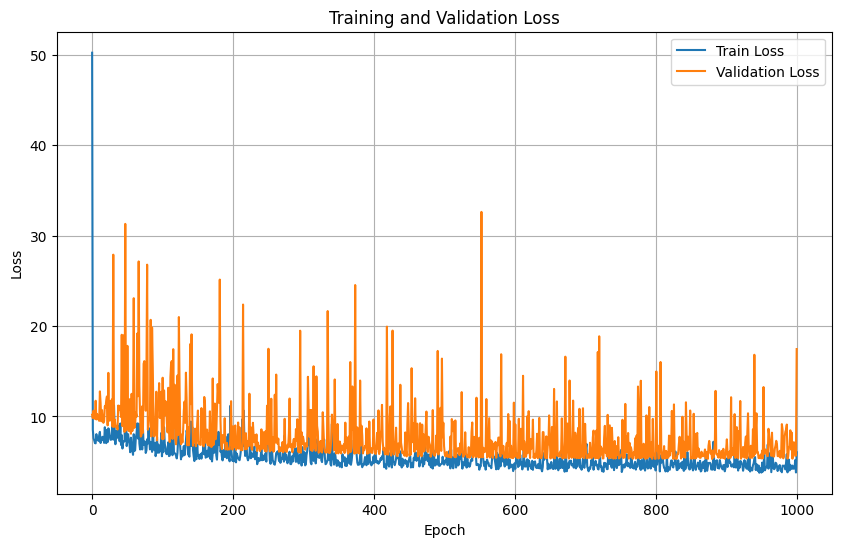

In [55]:
plot_losses(tl, vl, start_idx=0)

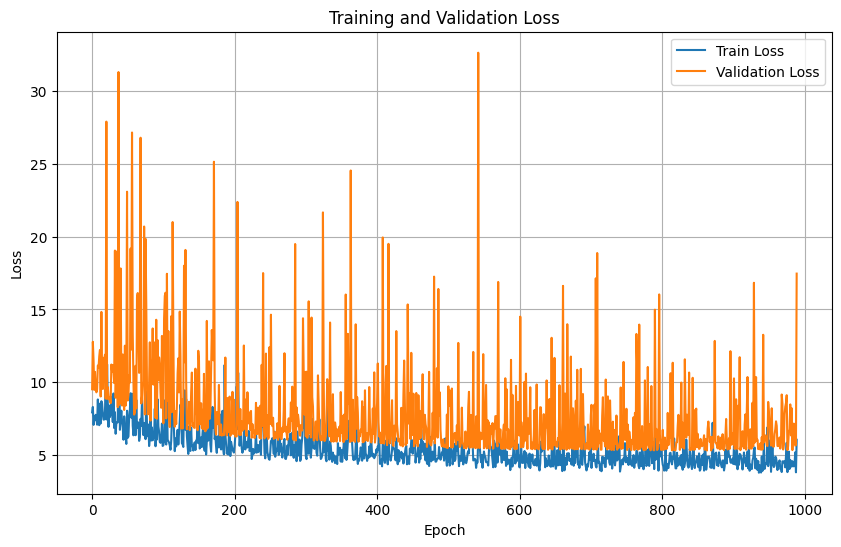

In [56]:
plot_losses(tl, vl, start_idx=10)

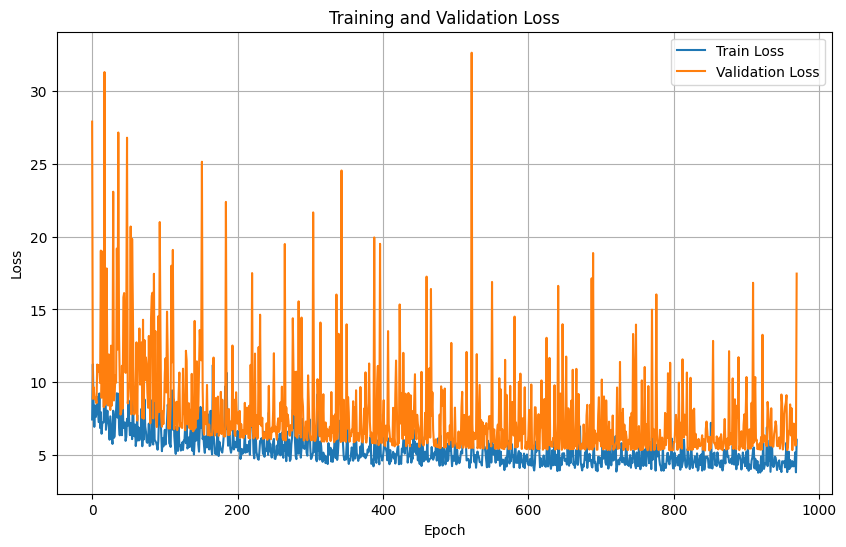

In [57]:
plot_losses(tl, vl, start_idx=30)

In [58]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [59]:
def make_preds(model, window):
  model.eval()
  predictions = []
  actuals = []

  with torch.inference_mode():
      for X, y in window.test:

          X = X.to(device)
          preds = model(X.flatten(start_dim=1))
          predictions.append(preds.cpu())
          actuals.append(y)

  predictions = torch.cat(predictions, dim=0)
  actuals = torch.cat(actuals, dim=0)
  return predictions, actuals

In [60]:
actuals, predictions  = make_preds(model, hourly_window)

In [61]:
test_loss = nn.MSELoss()(predictions, actuals)
print(f"Test Loss: {test_loss:.4f}")

Test Loss: 258.8128


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/loss.py:630: UserWarning: Using a target size (torch.Size([254, 1])) that is different to the input size (torch.Size([254, 1, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


In [62]:
def plot_preds(actuals, predictions, title, check_idx=0, xlim=None, ylim=None):

    # Convert tensors to NumPy
    if predictions.ndim == 1:
        pr = predictions.detach().cpu().numpy()
        pr = pr[:, None]

    elif predictions.ndim == 2:
        pr = predictions.detach().cpu().numpy()

    elif predictions.ndim == 3:
        pr = predictions.squeeze(-1).detach().cpu().numpy()

    # Convert actuals
    ac = actuals.detach().cpu().numpy()

    if ac.ndim == 3:
        ac = ac.squeeze(-1)

    # Select the appropriate series
    if pr.ndim == 2 and pr.shape[1] > 1:
        preds = pr[:, check_idx]
    else:
        preds = pr.squeeze()

    if ac.ndim == 2 and ac.shape[1] > 1:
        actuals = ac[:, check_idx]
    else:
        actuals = ac.squeeze()

    print("Actuals:", actuals.shape)
    print("Predictions:", preds.shape)

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.plot(actuals, label="Actuals")
    ax.plot(preds, label="Predictions")

    ax.set_title(title)

    if xlim is not None:
        ax.set_xlim(xlim)

    if ylim is not None:
        ax.set_ylim(ylim)

    ax.legend()
    ax.grid(True)
    plt.show()

Actuals: (254,)
Predictions: (254,)


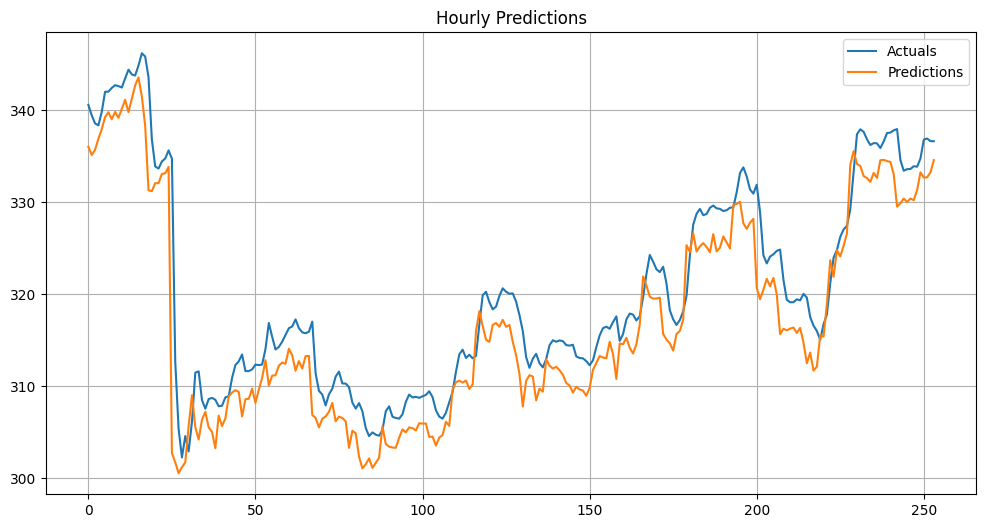

In [63]:
plot_preds(actuals, predictions, "Hourly Predictions")

Actuals: (254,)
Predictions: (254,)


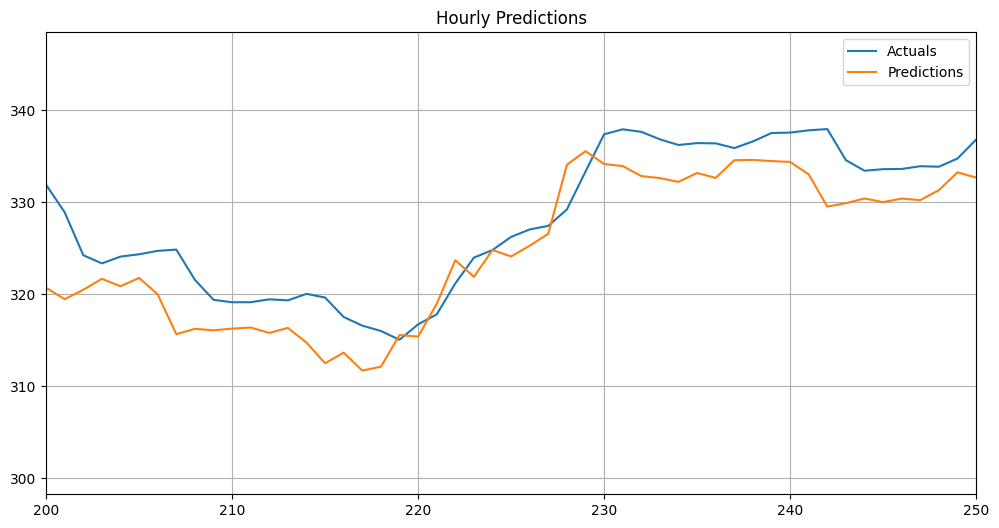

In [64]:
plot_preds(actuals, predictions, "Hourly Predictions", xlim=[200, 250])

Actuals: (254,)
Predictions: (254,)


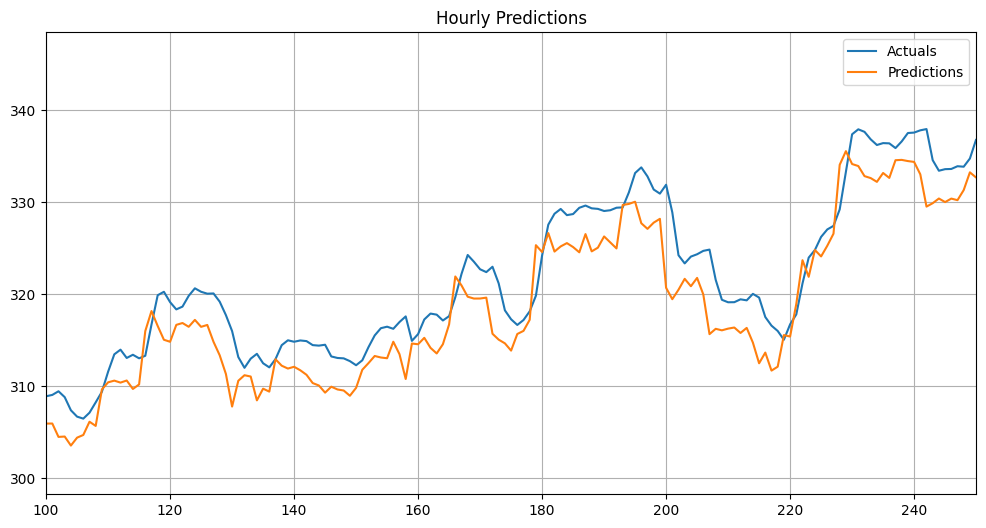

In [65]:
plot_preds(actuals, predictions, "Hourly Predictions", xlim=[100, 250])

In [66]:
model_2 =  nn.Sequential(
    nn.Flatten(start_dim=1),
    nn.Linear(7 * 12, 50),
    nn.ReLU(),
    nn.Linear(50, 3)
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model2 = model.to(device)

In [67]:
three_hour_window = DataWindow(input_width=7,label_width=3,shift=3)

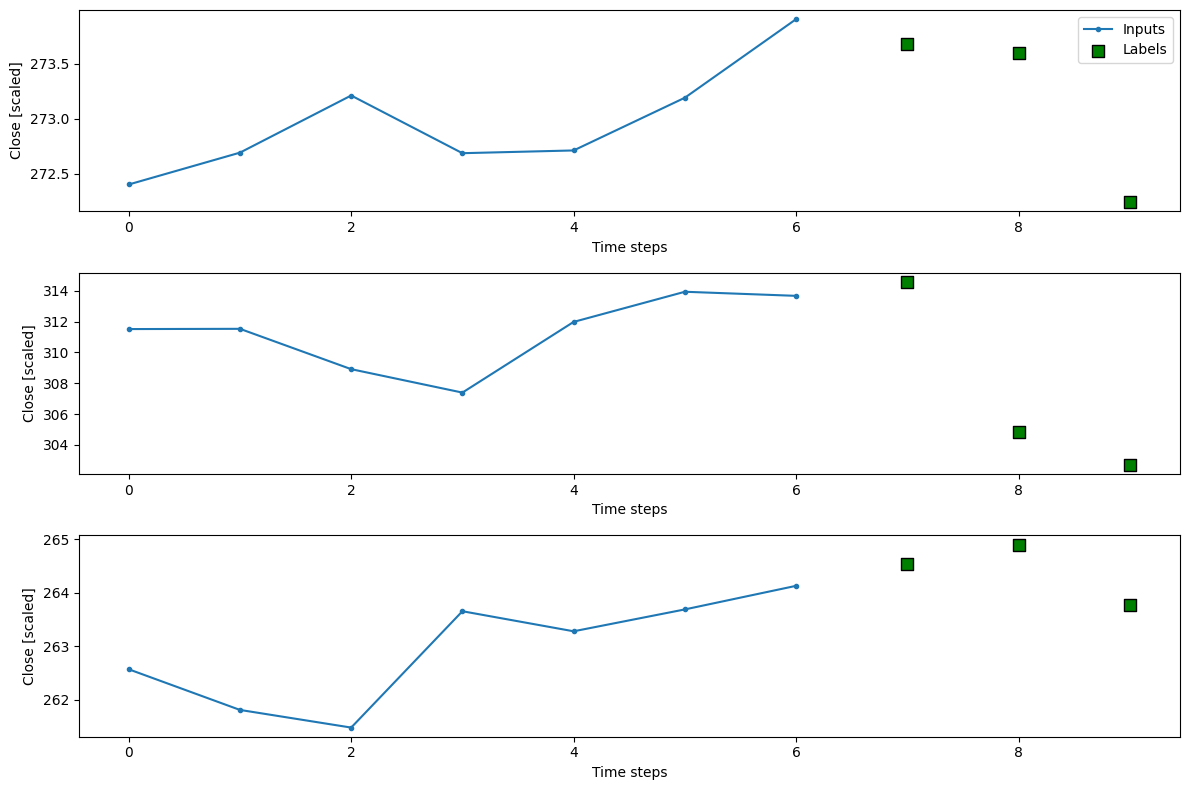

In [68]:
three_hour_window.plot()

inputs shape torch.Size([32, 7, 12])
inputs closes tensor([291.9950, 292.8750, 291.5800, 291.4601, 290.2250, 290.6400, 291.0800])
prediction (0,) tensor([[142.5950],
        [-52.2806],
        [ 70.8229]])
inputs shape torch.Size([32, 7, 12])
inputs closes tensor([251.3200, 251.9550, 253.4900, 258.1300, 257.5100, 257.4280, 257.5100])
prediction (1,) tensor([[147.1961],
        [-53.0812],
        [ 69.6194]])
inputs shape torch.Size([32, 7, 12])
inputs closes tensor([311.7750, 311.2350, 310.4700, 310.8300, 309.8200, 310.9300, 311.7000])
prediction (2,) tensor([[139.5229],
        [-52.0783],
        [ 72.7362]])


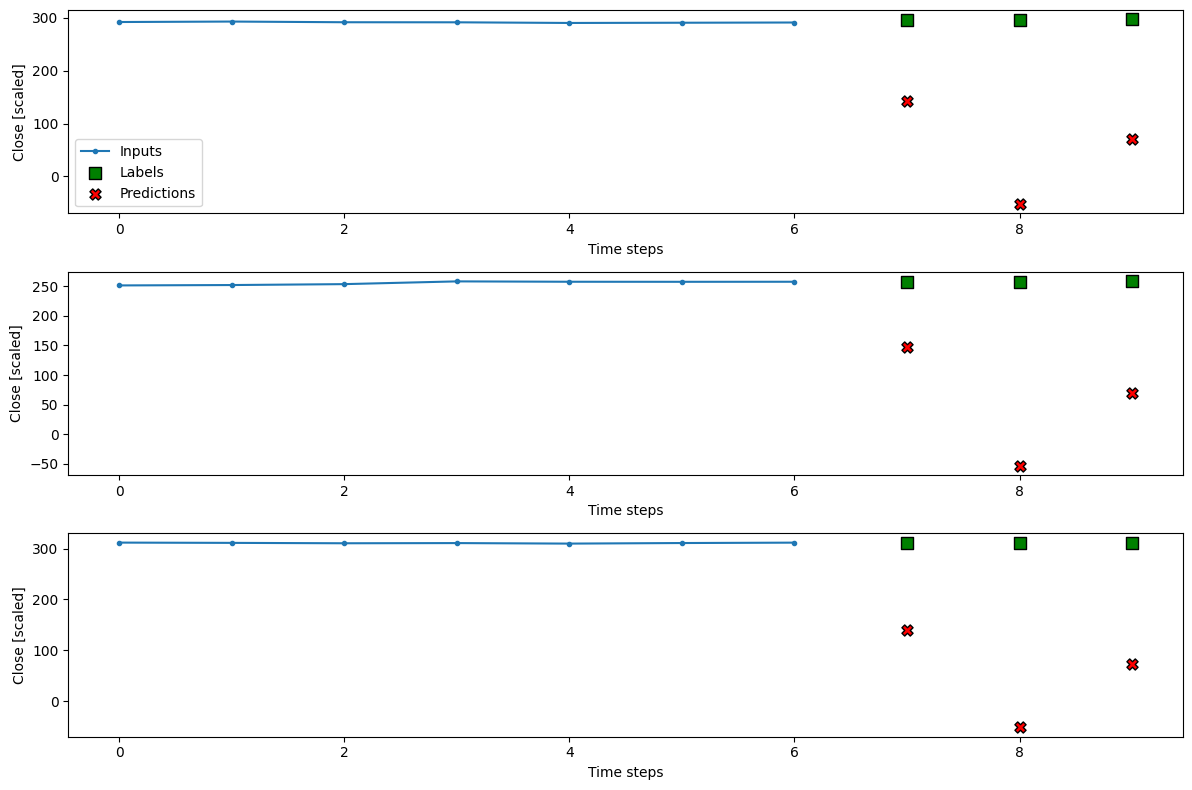

In [69]:
three_hour_window.plot(model=model_2)

In [70]:
train_loss, val_loss = train_loop(model_2, 1000, three_hour_window, 0.001)

  0%|          | 0/1000 [00:00<?, ?it/s]

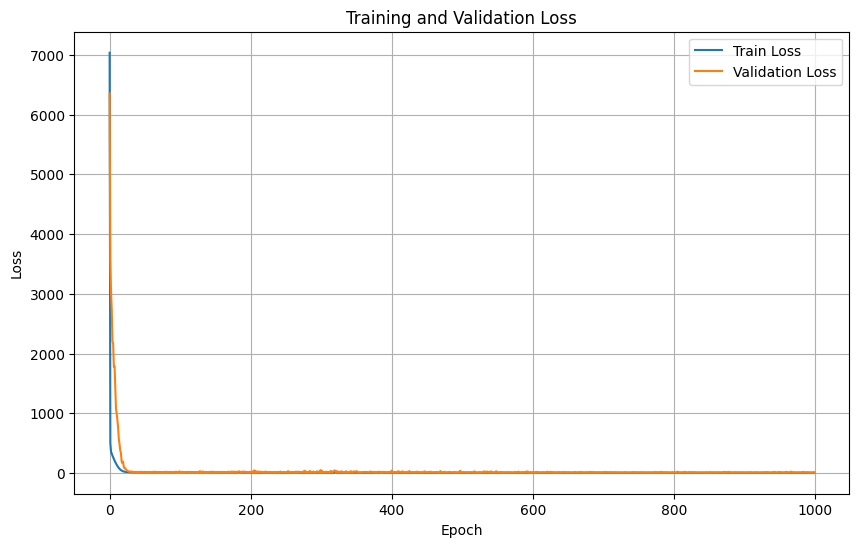

In [71]:
plot_losses(train_loss, val_loss)

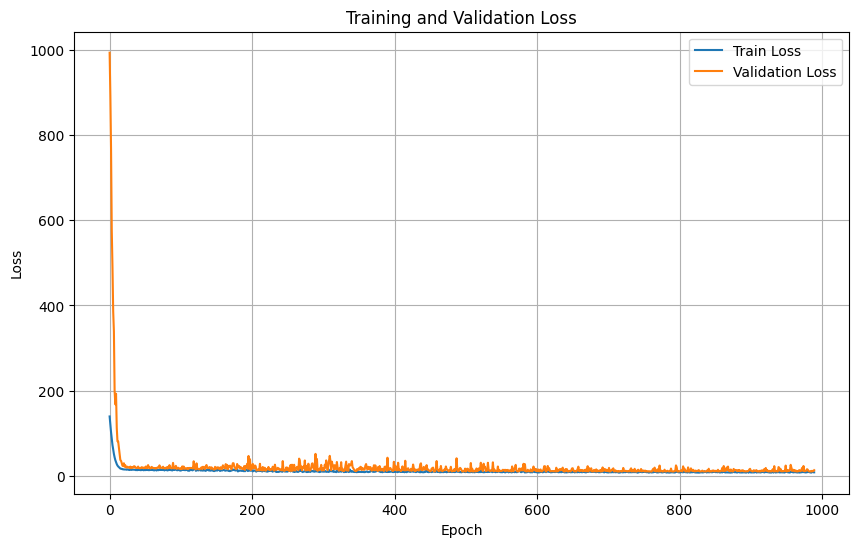

In [72]:
plot_losses(train_loss, val_loss, start_idx=10)

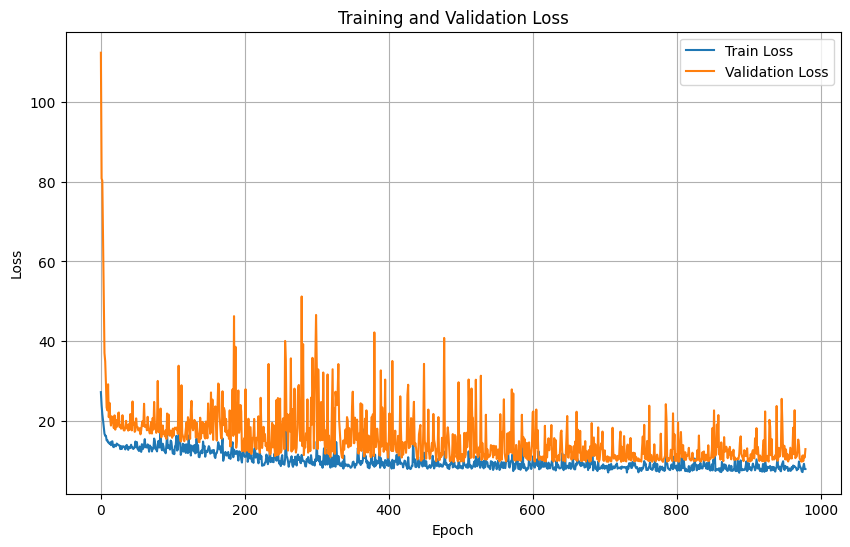

In [75]:
plot_losses(train_loss, val_loss, start_idx=20)

In [76]:
predictions3, actuals3  = make_preds(model_2, three_hour_window)

Actuals: (252,)
Predictions: (252,)


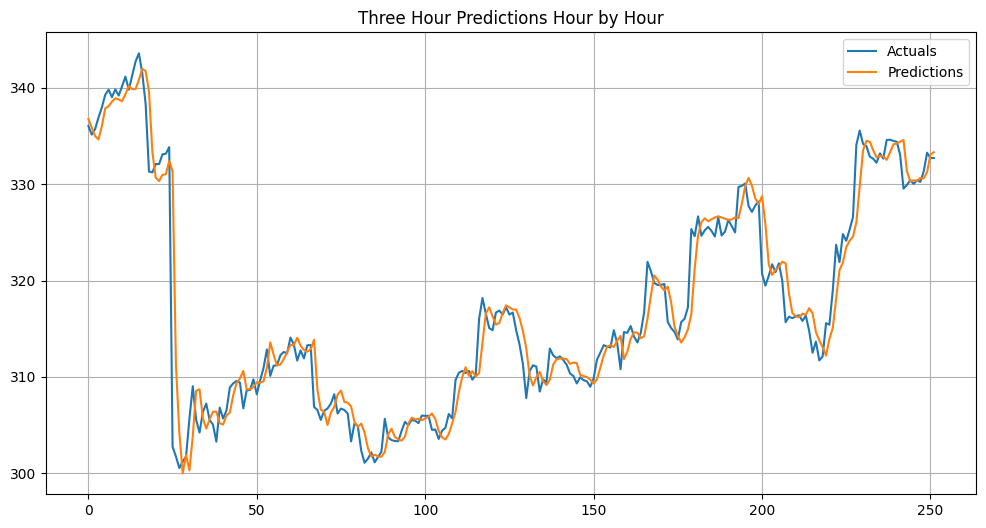

In [78]:
plot_preds(actuals3, predictions3, "Three Hour Predictions Hour by Hour")

Actuals: (252,)
Predictions: (252,)


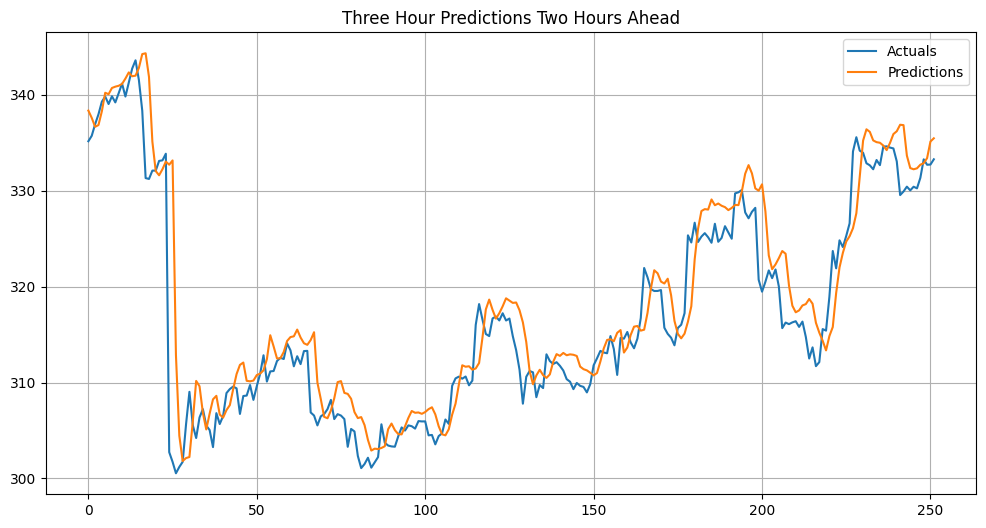

In [79]:
plot_preds(actuals3, predictions3, "Three Hour Predictions Two Hours Ahead", check_idx=1)

Actuals: (252,)
Predictions: (252,)


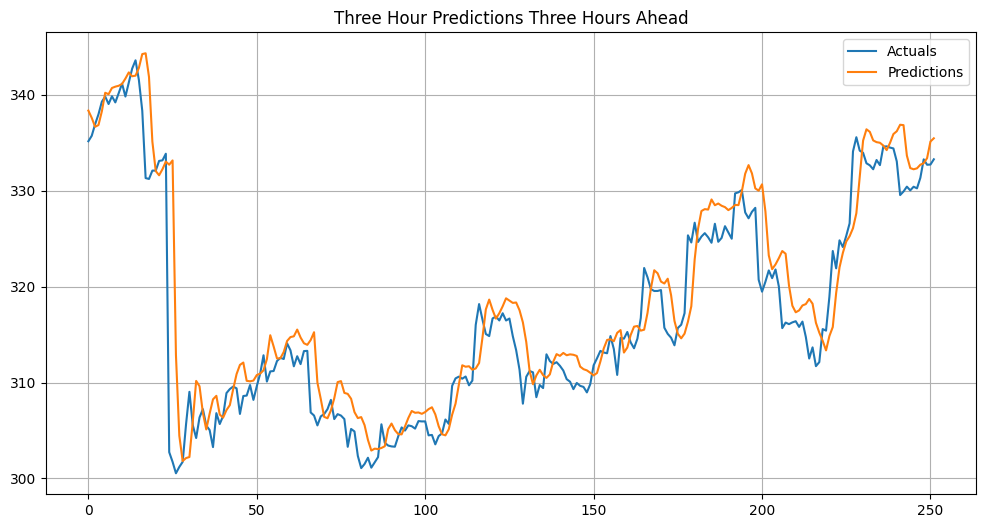

In [80]:
plot_preds(actuals3, predictions3, "Three Hour Predictions Three Hours Ahead", check_idx=1)

Actuals: (252,)
Predictions: (252,)


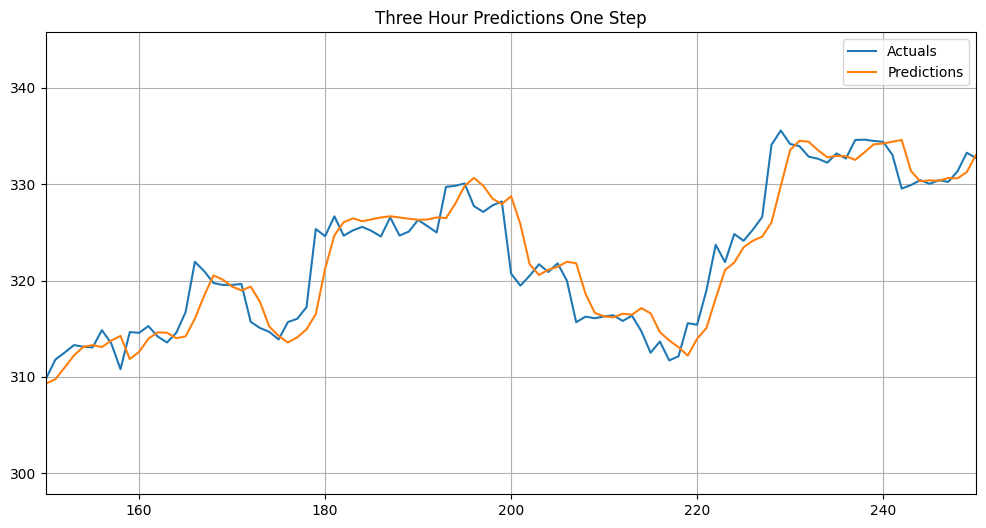

In [81]:
plot_preds(actuals3, predictions3, "Three Hour Predictions One Step", xlim=[150, 250])

Actuals: (252,)
Predictions: (252,)


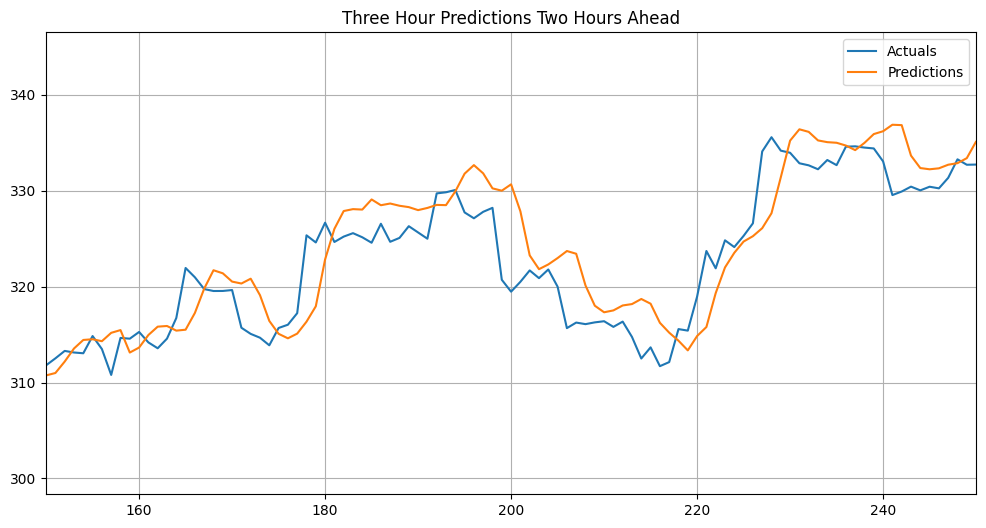

In [84]:
plot_preds(actuals3, predictions3, "Three Hour Predictions Two Hours Ahead", xlim=[150, 250], check_idx=1)

Actuals: (252,)
Predictions: (252,)


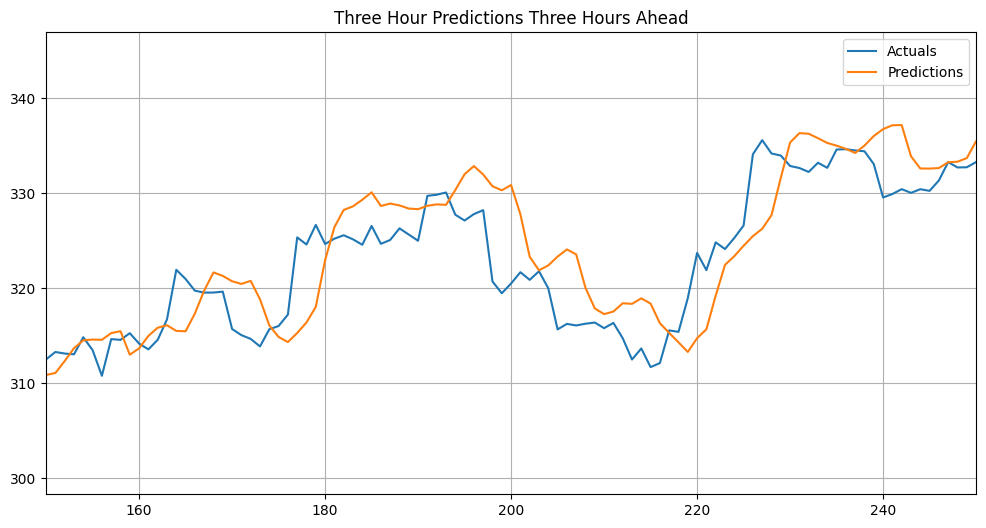

In [85]:
plot_preds(actuals3, predictions3, "Three Hour Predictions Three Hours Ahead", xlim=[150, 250], check_idx=2)

Actuals: (252,)
Predictions: (252,)


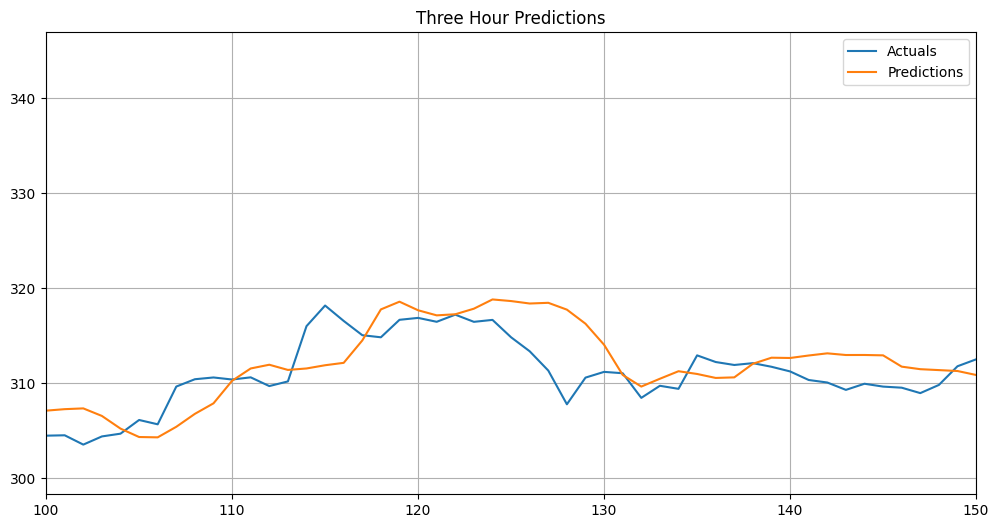

In [86]:
plot_preds(actuals3, predictions3, "Three Hour Predictions", xlim=[100, 150], check_idx=2)

In [88]:
test_loss = nn.MSELoss()(predictions3[:, 1], actuals3[:, 1])
print(f"Test Loss: {test_loss:.4f}")

Test Loss: 249.0306


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/loss.py:630: UserWarning: Using a target size (torch.Size([252, 1])) that is different to the input size (torch.Size([252])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


In [89]:
one_day_window = DataWindow(input_width=7,label_width=7,shift=7)

In [90]:
model_3 = make_model(7)

In [91]:
train_loss_3, val_loss_3 = train_loop(model_3, 1000, one_day_window, 0.001)

  0%|          | 0/1000 [00:00<?, ?it/s]

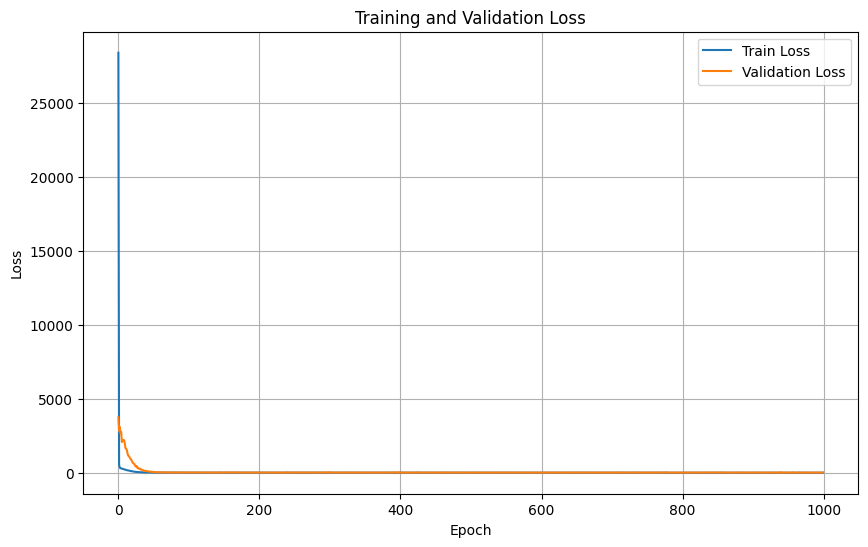

In [92]:
plot_losses(train_loss_3, val_loss_3)

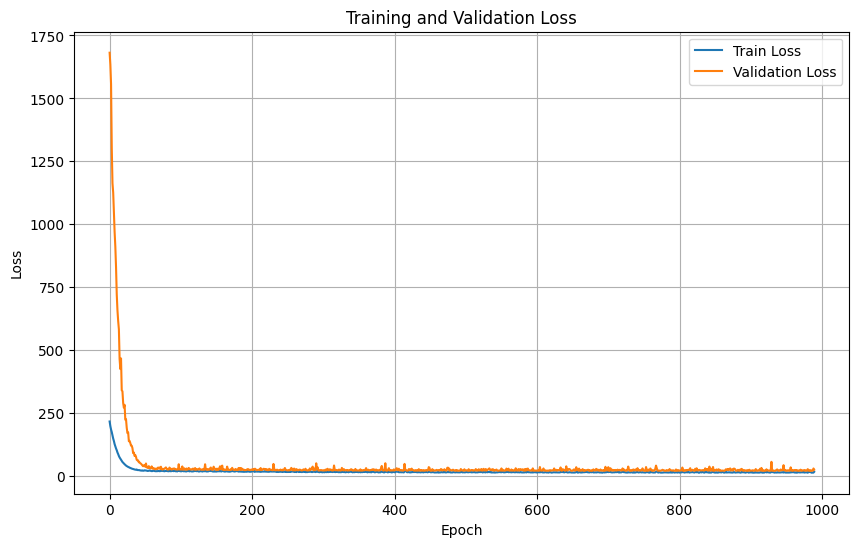

In [93]:
plot_losses(train_loss_3, val_loss_3, start_idx=10)

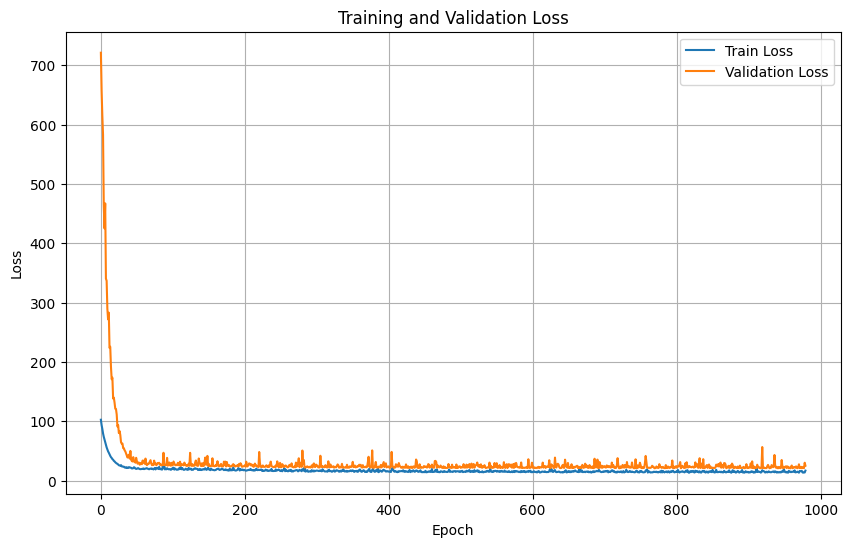

In [94]:
plot_losses(train_loss_3, val_loss_3, start_idx=20)

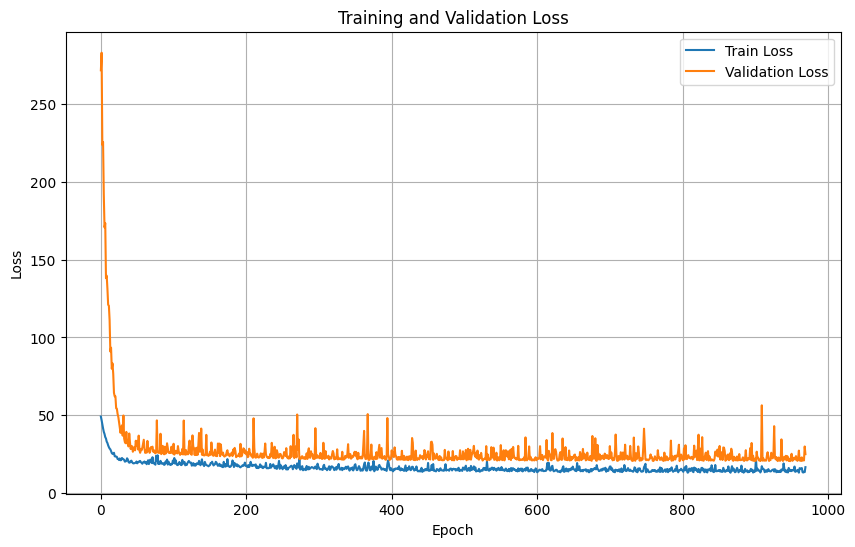

In [95]:
plot_losses(train_loss_3, val_loss_3, start_idx=30)

In [96]:
actuals_3, predictions_3  = make_preds(model_3, one_day_window)

Actuals: (248,)
Predictions: (248,)


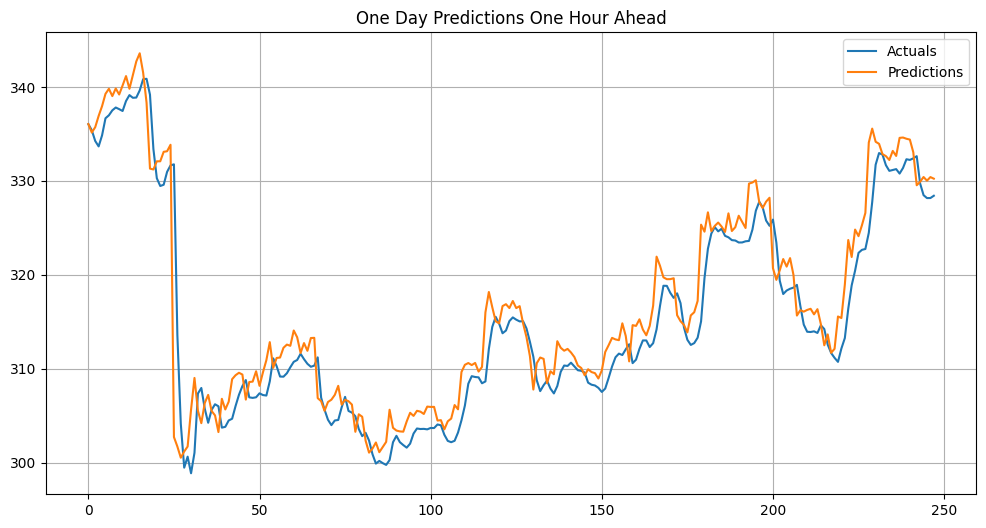

In [98]:
plot_preds(actuals_3, predictions_3, "One Day Predictions One Hour Ahead")

Actuals: (248,)
Predictions: (248,)


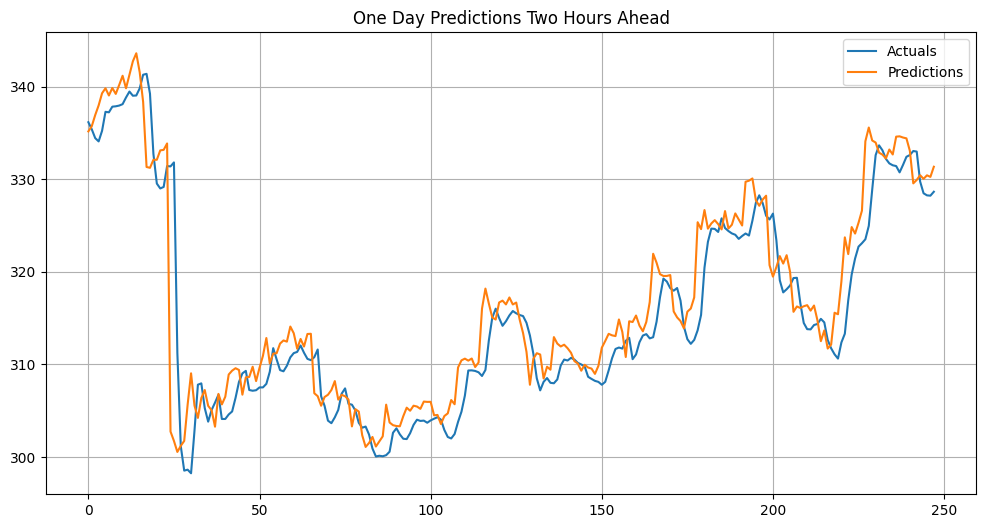

In [99]:
plot_preds(actuals_3, predictions_3, "One Day Predictions Two Hours Ahead", check_idx=1)

Actuals: (248,)
Predictions: (248,)


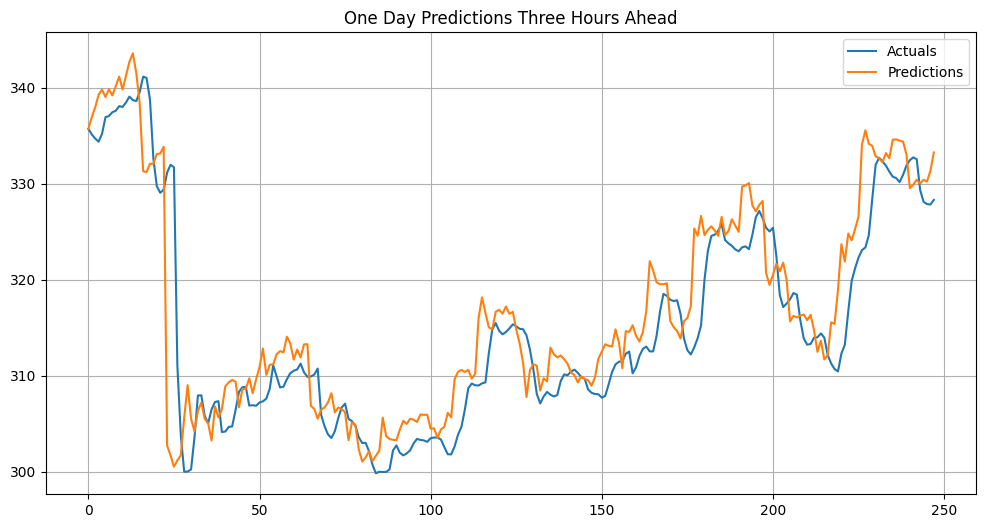

In [100]:
plot_preds(actuals_3, predictions_3, "One Day Predictions Three Hours Ahead", check_idx=2)

Actuals: (248,)
Predictions: (248,)


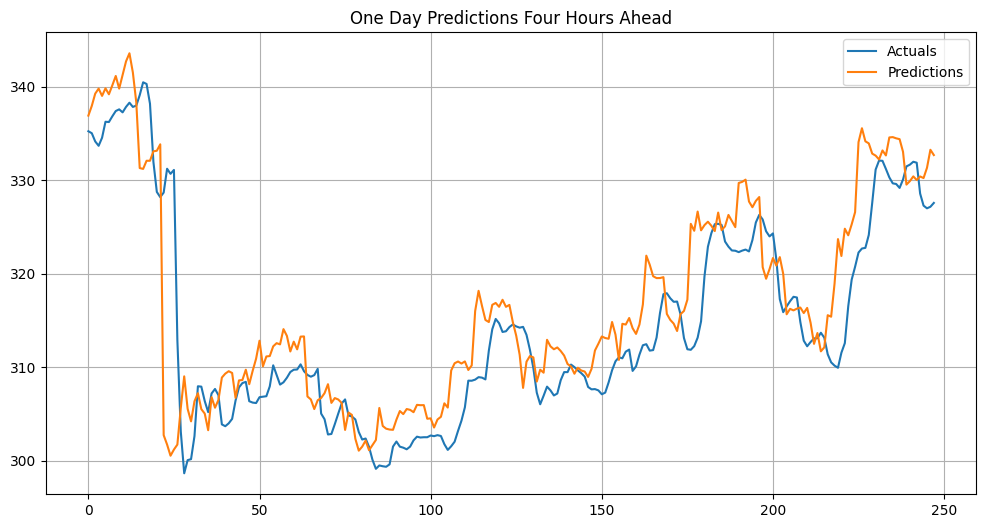

In [101]:
plot_preds(actuals_3, predictions_3, "One Day Predictions Four Hours Ahead", check_idx=3)

Actuals: (248,)
Predictions: (248,)


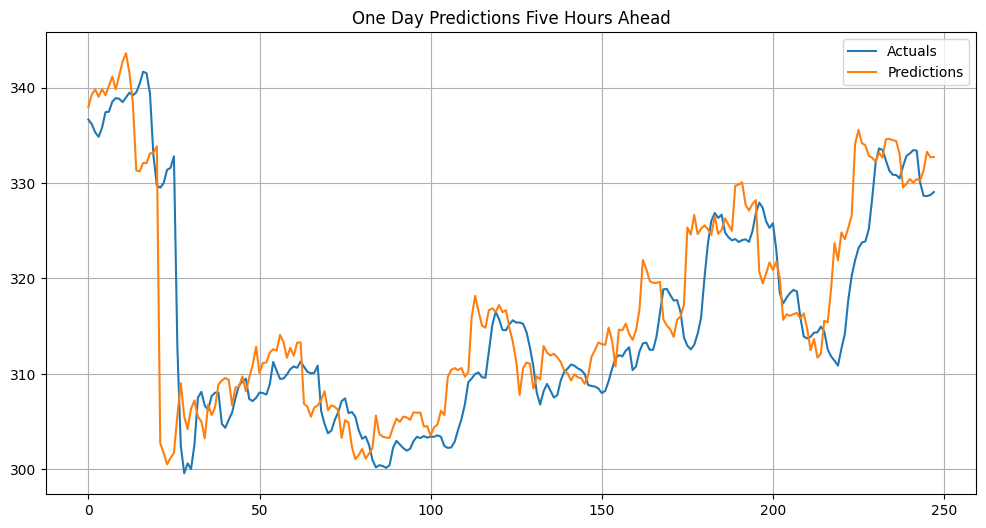

In [102]:
plot_preds(actuals_3, predictions_3, "One Day Predictions Five Hours Ahead", check_idx=4)

Actuals: (248,)
Predictions: (248,)


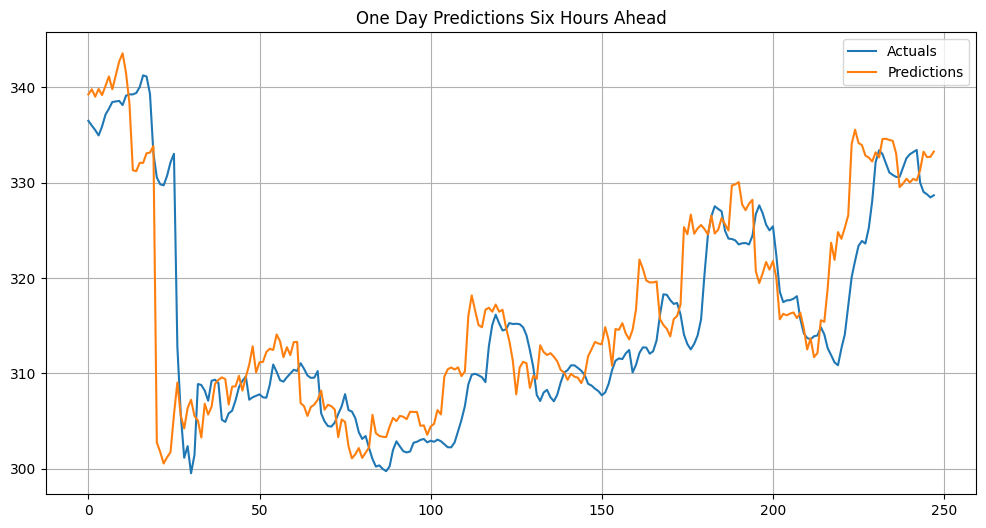

In [103]:
plot_preds(actuals_3, predictions_3, "One Day Predictions Six Hours Ahead", check_idx=5)

Actuals: (248,)
Predictions: (248,)


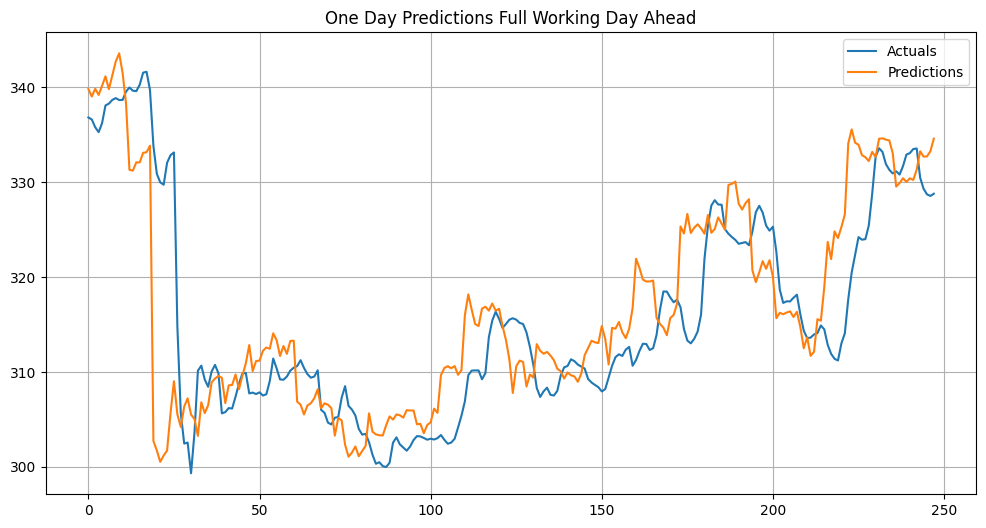

In [104]:
plot_preds(actuals_3, predictions_3, "One Day Predictions Full Working Day Ahead", check_idx=6)

In [105]:
from sklearn.metrics import mean_squared_error

def normalize_shape(data):

    if isinstance(data, torch.Tensor):
        data = data.detach().cpu().numpy()

    data = np.asarray(data)

    # Remove singleton dimensions
    data = np.squeeze(data)

    # Ensure 1D arrays become (n, 1)
    if data.ndim == 1:
        data = data[:, None]

    return data


def mean_squared_error_order(actuals, predictions):

    actuals = normalize_shape(actuals)
    predictions = normalize_shape(predictions)

    # Validate dimensions
    if actuals.shape != predictions.shape:
        raise ValueError(
            f"Shape mismatch: actuals {actuals.shape}, "
            f"predictions {predictions.shape}"
        )

    losses = []

    for i in range(predictions.shape[1]):
        loss = mean_squared_error(actuals[:, i], predictions[:, i])
        losses.append(loss)

    return losses

In [106]:
daily_predictions_loss = mean_squared_error_order(actuals_3, predictions_3)

In [107]:
def plot_MSE_scores(losses, title, xlim=[], ylim=[], labels=[]):
    colors = [
        "#1A365D",  # Midnight Blue (Professional base)
        "#0D9488",  # Teal Accent (Balanced contrast)
        "#059669",  # Emerald Green (Positive metrics)
        "#D97706",  # Warm Amber (Warnings / Highlights)
        "#DC2626",  # Coral Red (Critical / High priority)
        "#8B5CF6",  # Soft Lavender (Creative split)
        "#4B5563"   # Slate Gray (Neutral / Baseline)
    ]

    if not labels:
        labels = [f"Step {i + 1}" for i in range(len(losses))]
    fig, ax  = plt.subplots(figsize=(12, 6))
    ax.bar(labels, losses, color=colors[:len(losses)])
    ax.set_xlabel("Prediction Step Size")
    ax.set_ylabel("MSE")
    ax.set_title(title)
    if xlim:
        ax.set_xlim(xlim)
    if ylim:
        ax.set_ylim(ylim)
    plt.tight_layout()
    plt.show()

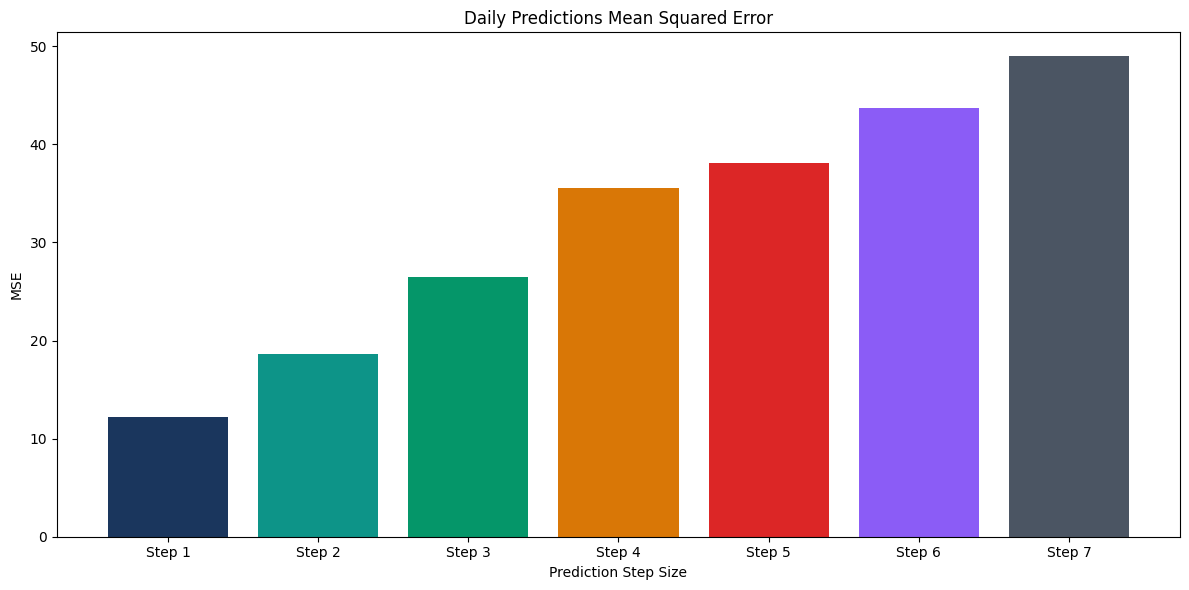

In [108]:
plot_MSE_scores(daily_predictions_loss, "Daily Predictions Mean Squared Error")

In [109]:
hourly_predictions_loss = mean_squared_error_order(actuals, predictions)

In [110]:
hourly_predictions_loss[0]

19.024219512939453

In [111]:
three_hour_predictions_loss = mean_squared_error_order(actuals3, predictions3)

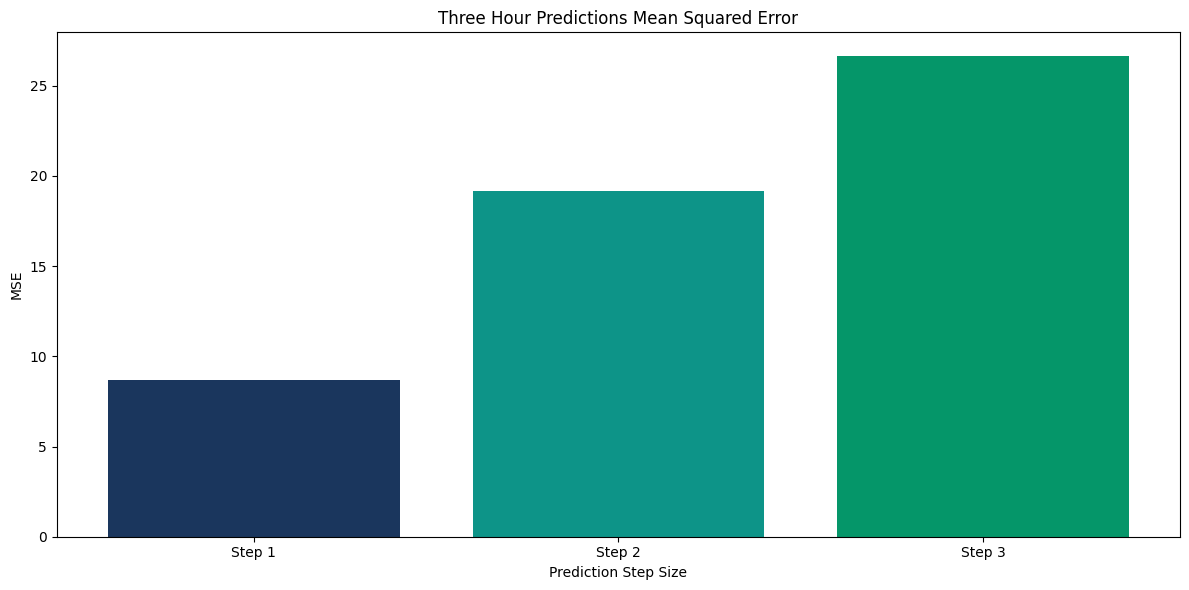

In [112]:
plot_MSE_scores(three_hour_predictions_loss, "Three Hour Predictions Mean Squared Error")

In [113]:
best_models = [hourly_predictions_loss[0], three_hour_predictions_loss[0], daily_predictions_loss[0]]

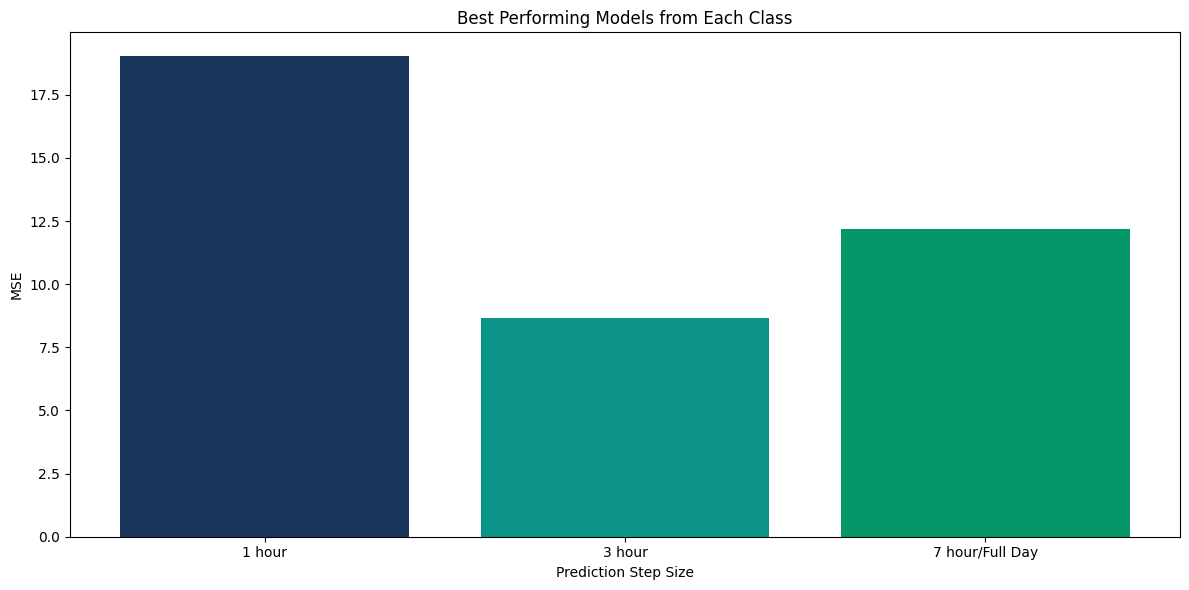

In [114]:
plot_MSE_scores(best_models, "Best Performing Models from Each Class", labels= ["1 hour", "3 hour", "7 hour/Full Day"])